## 6.7 Gradient Boosting and XGBoost

Gradient boosting is a different way of combining multiple decision tree models into one ensemble. 

In boosting, we start with a data set; then we train the first model; the first model makes predictions, then we look at the predictions, and what are the errors that this model is making. Based on these errors we train another model. Then this second model makes predictions again. This model also makes some errors. Then we train a third model that corrects the predictions of the second model; we repeat this, and do this for many itterations. Finally we combine multiple predictions into the **final prediction**. The training of the series of models is sequential. 

In this sequence of models, if we replace each model with a tree, we get the idea of boosted trees.

In [1]:
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 46.4 MB/s  0:00:01s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 18.7 MB/s  0:00:14 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]━━━ 1/2 [xgboost]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /usr/local/python/3.14.2/bin/python3 -m pip install --upgrade pip


In [1]:
import xgboost as xgb

In [2]:
# Environment setup

import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

# Data source

# data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv'
data = "CreditScoring.csv"

In [3]:
# Load Data into environment

!wget $data

--2026-11-01 19:41:44--  http://creditscoring.csv/
Resolving creditscoring.csv (creditscoring.csv)... failed: Name or service not known.
wget: unable to resolve host address ‘creditscoring.csv’


In [4]:
df = pd.read_csv(data)
df.head()

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [5]:
# Prepare the data for ML processing

df.columns = df.columns.str.lower()

In [6]:
# Re-encoding the categorical variables

status_values = {
    1: 'ok',
    2: 'default',
    0: 'unk'
}

df.status = df.status.map(status_values)

In [7]:
home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}

df.home = df.home.map(home_values)

marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}

df.marital = df.marital.map(marital_values)

records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df.records = df.records.map(records_values)

job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}

df.job = df.job.map(job_values)

In [8]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


In [9]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


In [10]:
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)

In [11]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4421.0,4408.0,4437.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,131.0,5403.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11573.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


In [12]:
# Make a new dataframe from the old dataframe using every record, so long as the status is not 'unk'. 
# Then reset the dataframe index

df = df[df.status != 'unk'].reset_index(drop=True)

In [13]:
df.count()

status       4454
seniority    4454
home         4454
time         4454
age          4454
marital      4454
records      4454
job          4454
expenses     4454
income       4420
assets       4407
debt         4436
amount       4454
price        4454
dtype: int64

In [14]:
# Split source data in to Train / Validation / Test

from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=11)

In [15]:
# We reset the indexes so they are fresh and unique in each dataframe:

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [16]:
# Preparing the Target Variable

y_train = (df_train.status == 'default').astype('int').values
y_val = (df_val.status == 'default').astype('int').values
y_test = (df_test.status == 'default').astype('int').values

In [17]:
# Delete status from the dataframes

del df_train['status']
del df_val['status']
del df_test['status']

Explain here please

`DictVectorizer` one-hot encodes the categorical features - it creates columns like job=partime and records=no - and leaves the numeric ones unchanged.

In [19]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score

In [20]:
# fill the missing values with 0

train_dicts = df_train.fillna(0).to_dict(orient='records')

# Use DictVectorizer to convert the dictionaries into a feature matrix

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

You really need to know what this does

In [21]:
val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val = dv.transform(val_dicts)

### DMatrix

Wrap our training data in a special data structure internal to XGBoost called DMatrix
DMatrix() is optimised for training XGBoost models 
`X_train` is feature matrix
`y_train` is target variable

In [22]:
features = list(dv.get_feature_names_out())

dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [23]:
# intel xeon cpu 5-1650 v3 3.50GHz number of cores: ; number of threads: 12
# https://xgboost.readthedocs.io/en/latest/parameter.html

xgb_params = {
    'eta': 0.3, # learning rate; how fast our model learns
    'max_depth': 6, # controls the size of the trees; default value is 6
    'min_child_weight': 1, # the same as min_samples_weight; how many observations we should have in a leaf node; default is 1

    'objective': 'binary:logistic', # there are many types of objectives; xgb boost can be used for different things
    'nthread': 12, # the parameter for parallelising and controlling the number of threads

    'seed': 1,
    'verbosity': 1, # controls what kind of warnings we have when we train our ; 1 means show only warnings
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200)

In [35]:
model.predict(dval)

array([4.31361720e-02, 4.27737366e-03, 6.75859279e-04, 9.65001211e-02,
       1.06018677e-03, 3.52140144e-03, 3.02975444e-04, 8.86651695e-01,
       7.88923874e-02, 1.87714177e-04, 1.40199602e-01, 9.93337035e-01,
       7.39668071e-01, 6.21446699e-04, 4.79650265e-03, 9.66348648e-01,
       6.52493036e-04, 7.03575373e-01, 2.45591067e-03, 4.67021428e-02,
       1.22672541e-03, 9.50312540e-02, 7.91552651e-04, 8.92462671e-01,
       9.53605831e-01, 5.45811979e-03, 7.28057563e-01, 9.51101445e-03,
       9.75149453e-01, 6.59366022e-04, 9.97828901e-01, 4.40825850e-01,
       8.96221623e-02, 7.87080005e-02, 4.88651101e-04, 1.47181518e-05,
       9.99814332e-01, 3.69971335e-01, 9.41287577e-01, 9.53366637e-01,
       3.15156989e-02, 9.95855629e-01, 3.51366447e-03, 3.14866394e-01,
       3.36176803e-04, 5.11976716e-04, 4.90001202e-01, 3.51968018e-04,
       4.59142635e-03, 6.04099594e-03, 6.19758648e-05, 1.90485697e-02,
       5.29917481e-04, 2.62436122e-01, 8.12831283e-01, 7.72655010e-02,
      

In [24]:
y_pred = model.predict(dval)

In [25]:
roc_auc_score(y_val, y_pred)

0.8045064299726334

Alexey got 0.8003166549611296

In [22]:
# 10 trees
model = xgb.train(xgb_params, dtrain, num_boost_round=10)
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.8156256811411687

XGBoost is prone to overfitting, so we need to be careful with the size of the trees and the number that we train.

### Watchlist

With XGBoost it is possible to monitor the training procedure, so that we can see what is happening at each stage. After each itteration, after each new tree is trained, we can immediately evaluate it on our evaluation data.

To do this we create a watch list. The watchlist contains a list of tuples.

In [23]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [29]:
xgb_params = {
    'eta': 0.3, 
    'max_depth': 6, 
    'min_child_weight': 1, 

    'objective': 'binary:logistic', 
    'eval_metric': 'auc',

    'nthread': 12, 
    'seed': 1,
    'verbosity': 1, 
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5, # print the evaluation every 5 steps
                 evals=watchlist
                )

[0]	train-auc:0.86632	val-auc:0.77998
[5]	train-auc:0.93359	val-auc:0.81150
[10]	train-auc:0.95391	val-auc:0.82002
[15]	train-auc:0.97087	val-auc:0.82220
[20]	train-auc:0.97677	val-auc:0.82239
[25]	train-auc:0.98440	val-auc:0.82074
[30]	train-auc:0.98805	val-auc:0.82061
[35]	train-auc:0.99239	val-auc:0.81804
[40]	train-auc:0.99474	val-auc:0.81732
[45]	train-auc:0.99627	val-auc:0.81413
[50]	train-auc:0.99753	val-auc:0.81320
[55]	train-auc:0.99811	val-auc:0.81140
[60]	train-auc:0.99893	val-auc:0.80818
[65]	train-auc:0.99924	val-auc:0.80696
[70]	train-auc:0.99955	val-auc:0.80710
[75]	train-auc:0.99979	val-auc:0.80802
[80]	train-auc:0.99987	val-auc:0.80813
[85]	train-auc:0.99993	val-auc:0.80761
[90]	train-auc:0.99995	val-auc:0.80782
[95]	train-auc:0.99997	val-auc:0.80870
[100]	train-auc:0.99999	val-auc:0.80839
[105]	train-auc:1.00000	val-auc:0.80735
[110]	train-auc:1.00000	val-auc:0.80730
[115]	train-auc:1.00000	val-auc:0.80779
[120]	train-auc:1.00000	val-auc:0.80570
[125]	train-auc:1.0000

"Step 25 is the best, step 10 is already quite good. We don't even need to train more models than 10; it is enough to stop at 10."

`capture` captures the output to a special object (similar to but not a string) from which we can extract information.

In [30]:
%%capture output

xgb_params = {
    'eta': 0.3, 
    'max_depth': 6, 
    'min_child_weight': 1, 

    'objective': 'binary:logistic', 
    'eval_metric': 'auc',

    'nthread': 12, 
    'seed': 1,
    'verbosity': 1, 
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5, # print the evaluation every 5 steps
                 evals=watchlist)

In [32]:
print(output.stdout)

[0]	train-auc:0.86632	val-auc:0.77998
[5]	train-auc:0.93359	val-auc:0.81150
[10]	train-auc:0.95391	val-auc:0.82002
[15]	train-auc:0.97087	val-auc:0.82220
[20]	train-auc:0.97677	val-auc:0.82239
[25]	train-auc:0.98440	val-auc:0.82074
[30]	train-auc:0.98805	val-auc:0.82061
[35]	train-auc:0.99239	val-auc:0.81804
[40]	train-auc:0.99474	val-auc:0.81732
[45]	train-auc:0.99627	val-auc:0.81413
[50]	train-auc:0.99753	val-auc:0.81320
[55]	train-auc:0.99811	val-auc:0.81140
[60]	train-auc:0.99893	val-auc:0.80818
[65]	train-auc:0.99924	val-auc:0.80696
[70]	train-auc:0.99955	val-auc:0.80710
[75]	train-auc:0.99979	val-auc:0.80802
[80]	train-auc:0.99987	val-auc:0.80813
[85]	train-auc:0.99993	val-auc:0.80761
[90]	train-auc:0.99995	val-auc:0.80782
[95]	train-auc:0.99997	val-auc:0.80870
[100]	train-auc:0.99999	val-auc:0.80839
[105]	train-auc:1.00000	val-auc:0.80735
[110]	train-auc:1.00000	val-auc:0.80730
[115]	train-auc:1.00000	val-auc:0.80779
[120]	train-auc:1.00000	val-auc:0.80570
[125]	train-auc:1.0000

In [33]:
s = output.stdout

In [34]:
s.split('\n')

['[0]\ttrain-auc:0.86632\tval-auc:0.77998',
 '[5]\ttrain-auc:0.93359\tval-auc:0.81150',
 '[10]\ttrain-auc:0.95391\tval-auc:0.82002',
 '[15]\ttrain-auc:0.97087\tval-auc:0.82220',
 '[20]\ttrain-auc:0.97677\tval-auc:0.82239',
 '[25]\ttrain-auc:0.98440\tval-auc:0.82074',
 '[30]\ttrain-auc:0.98805\tval-auc:0.82061',
 '[35]\ttrain-auc:0.99239\tval-auc:0.81804',
 '[40]\ttrain-auc:0.99474\tval-auc:0.81732',
 '[45]\ttrain-auc:0.99627\tval-auc:0.81413',
 '[50]\ttrain-auc:0.99753\tval-auc:0.81320',
 '[55]\ttrain-auc:0.99811\tval-auc:0.81140',
 '[60]\ttrain-auc:0.99893\tval-auc:0.80818',
 '[65]\ttrain-auc:0.99924\tval-auc:0.80696',
 '[70]\ttrain-auc:0.99955\tval-auc:0.80710',
 '[75]\ttrain-auc:0.99979\tval-auc:0.80802',
 '[80]\ttrain-auc:0.99987\tval-auc:0.80813',
 '[85]\ttrain-auc:0.99993\tval-auc:0.80761',
 '[90]\ttrain-auc:0.99995\tval-auc:0.80782',
 '[95]\ttrain-auc:0.99997\tval-auc:0.80870',
 '[100]\ttrain-auc:0.99999\tval-auc:0.80839',
 '[105]\ttrain-auc:1.00000\tval-auc:0.80735',
 '[110]\tt

In [35]:
line = s.split('\n')[0]

In [36]:
line.split('\t')

['[0]', 'train-auc:0.86632', 'val-auc:0.77998']

In [37]:
num_itr, train_auc, val_auc = line.split('\t')

In [38]:
int(num_itr.strip('[]'))

0

In [39]:
float(train_auc.split(':')[1])

0.86632

In [40]:
float(val_auc.split(':')[1])

0.77998

In [43]:
def parse_xgb_output(output):
    results = [] # afterthought: Turn it all into a dataframe
    tree = []
    aucs_train = []
    aucs_val = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        #tree.append(it)
        #aucs_train.append(train)
        #aucs_val.append(val)
        results.append((it, train, val))

    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    #return tree, aucs_train, aucs_val
    return df_results

In [44]:
df_score = parse_xgb_output(output)

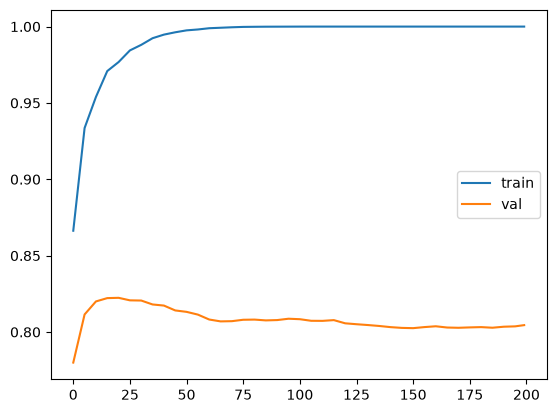

In [47]:
plt.plot(df_score.num_iter, df_score.train_auc, label='train')
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

The overfitting begins around the 60 round mark. Below, looking only at overfitting, we see a clear decline.

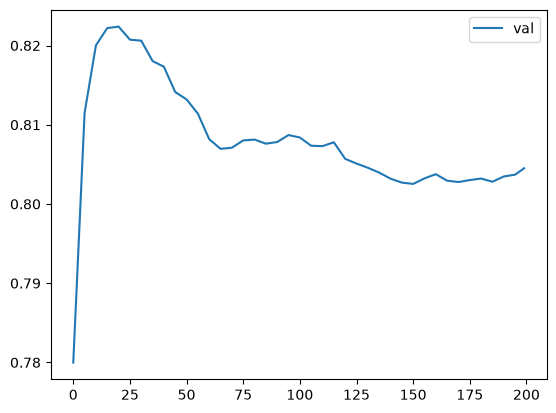

In [49]:
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

### XBoost Parameter Tuning

We will tune `eta`, `max_depth`, and `min_child weight`. 

ETA is also called "learning rate". When training models in series, and we combine the first model with the second model, ETA says how much **weight** the second model has.

`1.0` says all the predictions are used to correct the predictions of the first model.
`0.3` says 30% of the predictions are used to correct the predictions of the first model. This has the effect of moving the sequence in smaller steps.


In [70]:
# the dictionary called scores
# do this only once
scores = {}

In [80]:
%%capture output

xgb_params = {
    'eta': 0.01, 
    'max_depth': 6, 
    'min_child_weight': 1, 

    'objective': 'binary:logistic', 
    'eval_metric': 'auc',

    'nthread': 12, 
    'seed': 1,
    'verbosity': 1, 
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5, # print the evaluation every 5 steps
                 evals=watchlist)

In [81]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.01'

In [68]:
scores['eta=1.0']

,num_iter,train_auc,val_auc
0,0,0.86632,0.77998
1,5,0.96138,0.79351
2,10,0.98757,0.78052
3,15,0.99633,0.78434
4,20,0.99918,0.78544
5,25,0.99995,0.78589
6,30,1.00000,0.78753
7,35,1.00000,0.78704
8,40,1.00000,0.78967
9,45,1.00000,0.79441


In [82]:
scores.keys()

dict_keys(['eta=0.3', 'eta=1.0', 'eta=0.1', 'eta=0.05', 'eta=0.01'])

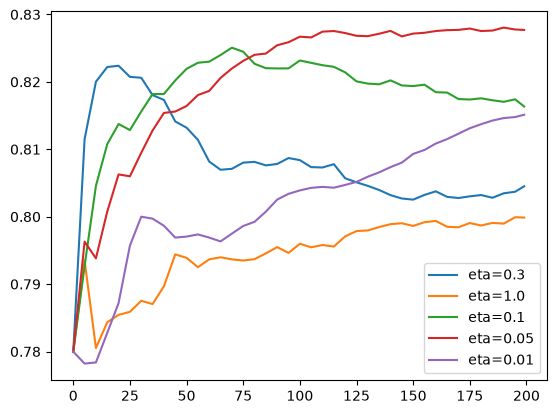

In [84]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)
plt.legend()

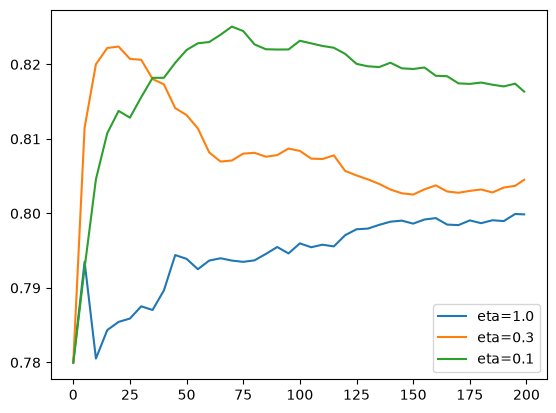

In [86]:
etas = ['eta=1.0', 'eta=0.3', 'eta=0.1']

for eta in etas:
    df_score = scores[eta]
    plt.plot(df_score.num_iter, df_score.val_auc, label=eta)
plt.legend()

Alexey usually tunes these parameters in this order:
1. ETA
2. max_depth
3. min_child_weight (which is min_samples_leaf in RF)

Next we will tune the max_depth parameter

In [90]:
scores = {}

In [98]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 4, 
    'min_child_weight': 1, 

    'objective': 'binary:logistic', 
    'eval_metric': 'auc',

    'nthread': 12, 
    'seed': 1,
    'verbosity': 1, 
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5, # print the evaluation every 5 steps
                 evals=watchlist)

In [99]:
key = 'max_depth=%s' % (xgb_params['max_depth'])
scores[key] = parse_xgb_output(output)
key

'max_depth=4'

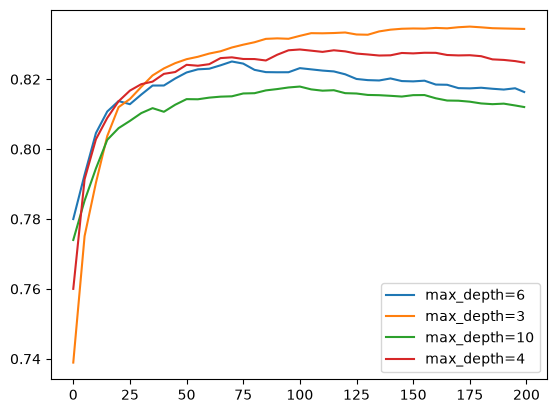

In [100]:
for max_depth, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=max_depth)
plt.legend()

In [101]:
del scores['max_depth=10']

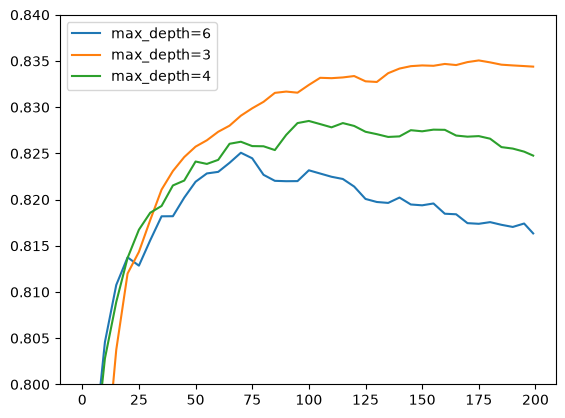

In [102]:
for max_depth, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=max_depth)
plt.ylim(0.8, 0.84) # limit the range of y
plt.legend()

What we learn is that max depth of 3 is the best depth for this one.

In [103]:
scores = {}

In [108]:
%%capture output

xgb_params = {
    'eta': 0.1, 
    'max_depth': 3, 
    'min_child_weight': 30, 

    'objective': 'binary:logistic', 
    'eval_metric': 'auc',

    'nthread': 12, 
    'seed': 1,
    'verbosity': 1, 
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5, # print the evaluation every 5 steps
                 evals=watchlist)

In [109]:
key = 'min_child_weight=%s' % (xgb_params['min_child_weight'])
scores[key] = parse_xgb_output(output)
key

'min_child_weight=30'

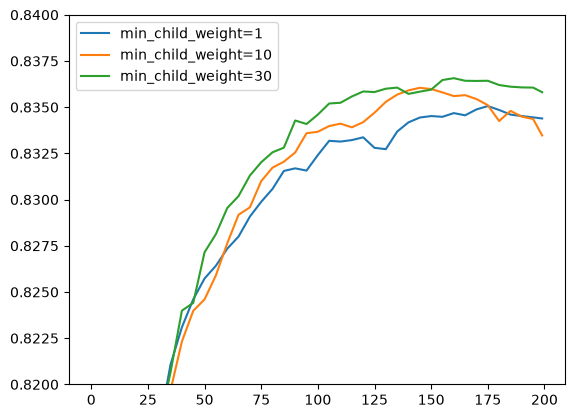

In [112]:
for min_child_weight, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=min_child_weight)
plt.ylim(0.82, 0.84) # limit the range of y
plt.legend()

Zooming in very close, we see that a `min_child_weight` of 30 is always better than a `min_child_weight` of 10.

Also, 175 iterations seems like a good spot, so we will train our model for 175 iterations.

In [ ]:
# Final model

xgb_params = {
    'eta': 0.1, 
    'max_depth': 3, 
    'min_child_weight': 30, 

    'objective': 'binary:logistic', 
    'eval_metric': 'auc',

    'nthread': 12, 
    'seed': 1,
    'verbosity': 1, 
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175)

`subsample` and `colsample_bytree` area also important parameters to tune.

In random forest, every decision tree can get a subset of columns. `colsample_bytree` designated how many freature bytrees each iteration gets.

`subsample` is similar, but instead of sampling columns, we are sampling rows. With a setting of 0.5, at each iteration, instead of getting all of the data, we are getting only 50% of the data.

## 6.9 Selecting the Best Model

So far we have trained three different tree-based models.
- Decision Tree Classifier
- Random Forest Classifier
- XGBoost Method Model

XGBoost typically gives better performance for tabular data, but it is more complicated and a greater risk of overfitting.

In [30]:
# Necessary Environment

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [29]:
# Best Decision Tree Classifier

dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",15
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [35]:
y_pred = dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.7848562640769174

In [33]:
# Best XGBoost Model

xgb_params = {
    'eta': 0.1, 
    'max_depth': 3, 
    'min_child_weight': 30, 

    'objective': 'binary:logistic', 
    'eval_metric': 'auc',

    'nthread': 12, 
    'seed': 1,
    'verbosity': 1, 
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175)

In [38]:
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.836426218788598

In [32]:
# Best Random Forest Classifier
rf= RandomForestClassifier(n_estimators=200,
                           max_depth=10,
                           min_samples_leaf=3,
                           random_state=1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [36]:
y_pred = rf.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.8246258264512848

In [39]:
df_full_train

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
3668,ok,22,owner,48,48,married,no,fixed,60,110.0,3000.0,0.0,1000,1460
2540,default,8,other,60,41,married,no,freelance,45,62.0,0.0,0.0,1800,2101
279,ok,2,parents,36,19,married,no,fixed,35,162.0,4000.0,100.0,400,570
3536,ok,1,owner,12,61,married,no,others,45,103.0,20000.0,0.0,300,650
3866,ok,13,owner,60,27,married,no,fixed,35,253.0,7000.0,0.0,1060,1750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
332,default,4,owner,60,47,married,no,freelance,75,0.0,13500.0,0.0,1900,1976
1293,ok,2,rent,60,28,single,no,fixed,45,101.0,0.0,0.0,1300,1333
4023,ok,2,parents,36,25,single,no,fixed,35,110.0,0.0,0.0,500,1200
3775,ok,4,other,60,25,single,no,fixed,35,162.0,0.0,0.0,1800,2999


In [40]:
df_full_train = df_full_train.reset_index(drop=True)

In [42]:
y_full_train = (df_full_train.status == 'default').astype(int).values

In [43]:
y_full_train 

array([0, 1, 0, ..., 0, 0, 1], shape=(3563,))

In [44]:
del df_full_train['status']

In [48]:
dicts_full_train = df_full_train.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

dicts_test = df_test.to_dict(orient='records')
X_test = dv.transform(dicts_test)

In [52]:
dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train,
                    feature_names=list(dv.get_feature_names_out())) # error for get_feature_names()

dtest = xgb.DMatrix(X_test, feature_names=list(dv.get_feature_names_out())) # error for get_feature_names()

In [53]:
xgb_params = {
    'eta': 0.1, 
    'max_depth': 3, 
    'min_child_weight': 30, 

    'objective': 'binary:logistic', 
    'eval_metric': 'auc',

    'nthread': 12, 
    'seed': 1,
    'verbosity': 1, 
}

model = xgb.train(xgb_params, dfulltrain, num_boost_round=175)

In [54]:
y_pred = model.predict(dtest)

In [55]:
y_pred[:10]

array([0.36805403, 0.24811943, 0.07960184, 0.1874363 , 0.34177607,
       0.27424088, 0.00615192, 0.02008395, 0.2631346 , 0.29128236],
      dtype=float32)

Check 6.11 Explore More!